In [ ]:
import zipfile
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, applications, optimizers
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# 1. Extract the uploaded zip file
zip_path = 'Hand_digits.zip'
extract_dir = 'Hand_digits_dataset'

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
        print("Dataset extracted successfully.")

# 2. Locate and load the .npy files
# Adjust the path below if your zip nested the files in another folder (like 'Sign-language-digits-dataset')
base_path = os.path.join(extract_dir, 'Sign-language-digits-dataset')
if not os.path.exists(base_path):
    base_path = extract_dir # Fallback if not nested

X_raw = np.load(os.path.join(base_path, 'X.npy')) # Shape: (2062, 64, 64)
Y = np.load(os.path.join(base_path, 'Y.npy'))     # Shape: (2062, 10)

# 3. Reshape and format for CNNs
# Custom CNNs can take 1 channel (Grayscale)
X_gray = X_raw.reshape(-1, 64, 64, 1)

# Pre-trained models (like MobileNet/VGG) require 3 channels (RGB)
# We repeat the grayscale channel 3 times
X_rgb = np.repeat(X_gray, 3, axis=-1)

# Split into Training (70%), Validation (15%), and Test (15%)
X_train, X_temp, Y_train, Y_temp = train_test_split(X_rgb, Y, test_size=0.3, random_state=42)
X_val, X_test, Y_val, Y_test = train_test_split(X_temp, Y_temp, test_size=0.5, random_state=42)

print(f"Training data shape: {X_train.shape}")

Dataset extracted successfully.
Training data shape: (1443, 64, 64, 3)


In [ ]:
def build_custom_cnn(input_shape=(64, 64, 3), num_classes=10):
    model = models.Sequential([
        layers.InputLayer(input_shape=input_shape),

        # Block 1
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Block 2
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Block 3
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.3),

        # Classifier
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

custom_model = build_custom_cnn()
print("Training Custom CNN...")
history_custom = custom_model.fit(X_train, Y_train, epochs=30, batch_size=32, validation_data=(X_val, Y_val), verbose=1)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Training Custom CNN...
Epoch 1/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 22s 416ms/step - accuracy: 0.4220 - loss: 2.6442 - val_accuracy: 0.1100 - val_loss: 4.2322
Epoch 2/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 19s 392ms/step - accuracy: 0.6410 - loss: 1.0396 - val_accuracy: 0.1100 - val_loss: 9.1977
Epoch 3/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 24s 471ms/step - accuracy: 0.7367 - loss: 0.7689 - val_accuracy: 0.1100 - val_loss: 9.9742
Epoch 4/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 38s 390ms/step - accuracy: 0.8025 - loss: 0.5738 - val_accuracy: 0.1100 - val_loss: 6.5711
Epoch 5/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 21s 402ms/step - accuracy: 0.8392 - loss: 0.4551 - val_accuracy: 0.3010 - val_loss: 3.2949
Epoch 6/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 18s 392ms/step - accuracy: 0.8448 - loss: 0.4561 - val_accuracy: 0.4142 - val_loss: 2.1666
Epoch 7/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 18s 386ms/step - accuracy: 0.8607 - loss: 0.3990 - val_accuracy: 0.3528 - val_loss: 2.4013
Epoch 8/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 19s 404ms/step - accuracy: 0.8898 - 

In [ ]:
def build_feature_extractor(input_shape=(64, 64, 3), num_classes=10):
    # Load MobileNetV2 without the top classification layer
    base_model = applications.MobileNetV2(input_shape=input_shape, include_top=False, weights='imagenet')

    # Freeze the base model
    base_model.trainable = False

    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model, base_model

tl_model, base_model = build_feature_extractor()
print("Training Transfer Learning (Feature Extractor)...")
history_tl = tl_model.fit(X_train, Y_train, epochs=20, batch_size=32, validation_data=(X_val, Y_val), verbose=1)

/tmp/ipykernel_8276/509325313.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = applications.MobileNetV2(input_shape=input_shape, include_top=False, weights='imagenet')


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Transfer Learning (Feature Extractor)...
Epoch 1/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 12s 158ms/step - accuracy: 0.3950 - loss: 1.7775 - val_accuracy: 0.6764 - val_loss: 1.1178
Epoch 2/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - accuracy: 0.6223 - loss: 1.1024 - val_accuracy: 0.7120 - val_loss: 0.8649
Epoch 3/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 143ms/step - accuracy: 0.7166 - loss: 0.8526 - val_accuracy: 0.7508 - val_loss: 0.7762
Epoch 4/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - accuracy: 0.7505 - loss: 0.7184 - val_accuracy: 0.7735 - val_loss: 0.7240
Epoch 5/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 104ms/step - accuracy: 0.8032 - loss: 0.6041 - val_accuracy: 0.7638 - val_loss: 0.6553
Epoch 6/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - accuracy: 0.8365 - loss: 0.4844 - val_accuracy: 0.8058 - val_loss: 0.6413
Epoch 7/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 101ms/step - accuracy: 0.8545 - loss: 0.4331 - val_accuracy: 0.7670 - val_loss: 0.6360
Epoc

In [ ]:
# Unfreeze the base model
base_model.trainable = True

# Let's freeze the bottom 100 layers and only fine-tune the top layers
for layer in base_model.layers[:100]:
    layer.trainable = False

# Recompile with a strictly lower learning rate for fine-tuning
tl_model.compile(optimizer=optimizers.Adam(learning_rate=1e-5),
                 loss='categorical_crossentropy',
                 metrics=['accuracy'])

print("Fine-tuning the model...")
history_fine = tl_model.fit(X_train, Y_train, epochs=15, batch_size=32, validation_data=(X_val, Y_val), verbose=1)

Fine-tuning the model...
Epoch 1/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 27s 285ms/step - accuracy: 0.2918 - loss: 4.7097 - val_accuracy: 0.8155 - val_loss: 0.6471
Epoch 2/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 19s 245ms/step - accuracy: 0.3326 - loss: 3.9097 - val_accuracy: 0.8026 - val_loss: 0.6686
Epoch 3/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 248ms/step - accuracy: 0.3673 - loss: 3.4874 - val_accuracy: 0.8123 - val_loss: 0.7014
Epoch 4/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 12s 266ms/step - accuracy: 0.3929 - loss: 3.0143 - val_accuracy: 0.7864 - val_loss: 0.7402
Epoch 5/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 12s 262ms/step - accuracy: 0.4283 - loss: 2.6695 - val_accuracy: 0.7605 - val_loss: 0.7626
Epoch 6/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 235ms/step - accuracy: 0.4629 - loss: 2.3945 - val_accuracy: 0.7638 - val_loss: 0.7910
Epoch 7/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 242ms/step - accuracy: 0.4879 - loss: 2.1313 - val_accuracy: 0.7508 - val_loss: 0.7994
Epoch 8/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 247ms/step - accuracy: 0.4976 

In [ ]:
def analyze_performance(X_data, Y_data):
    data_fractions = [0.25, 0.5, 1.0] # 25%, 50%, 100% of training data
    results = {}

    for frac in data_fractions:
        # Subset the training data
        subset_size = int(len(X_data) * frac)
        X_sub, Y_sub = X_data[:subset_size], Y_data[:subset_size]

        print(f"\n--- Testing with {frac*100}% of training data ({subset_size} samples) ---")

        # Test Custom CNN
        temp_custom = build_custom_cnn()
        temp_custom.fit(X_sub, Y_sub, epochs=15, batch_size=32, verbose=0)
        custom_loss, custom_acc = temp_custom.evaluate(X_test, Y_test, verbose=0)

        # Test Feature Extractor
        temp_tl, _ = build_feature_extractor()
        temp_tl.fit(X_sub, Y_sub, epochs=15, batch_size=32, verbose=0)
        tl_loss, tl_acc = temp_tl.evaluate(X_test, Y_test, verbose=0)

        results[frac] = {'Custom': custom_acc, 'Transfer Learning': tl_acc}
        print(f"Custom CNN Accuracy: {custom_acc:.4f} | Transfer Learning Accuracy: {tl_acc:.4f}")

    return results

# Run the analysis
analysis_results = analyze_performance(X_train, Y_train)


--- Testing with 25.0% of training data (360 samples) ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/tmp/ipykernel_8276/509325313.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = applications.MobileNetV2(input_shape=input_shape, include_top=False, weights='imagenet')


Custom CNN Accuracy: 0.1000 | Transfer Learning Accuracy: 0.6419

--- Testing with 50.0% of training data (721 samples) ---
Custom CNN Accuracy: 0.5935 | Transfer Learning Accuracy: 0.7097

--- Testing with 100.0% of training data (1443 samples) ---
Custom CNN Accuracy: 0.7355 | Transfer Learning Accuracy: 0.7742


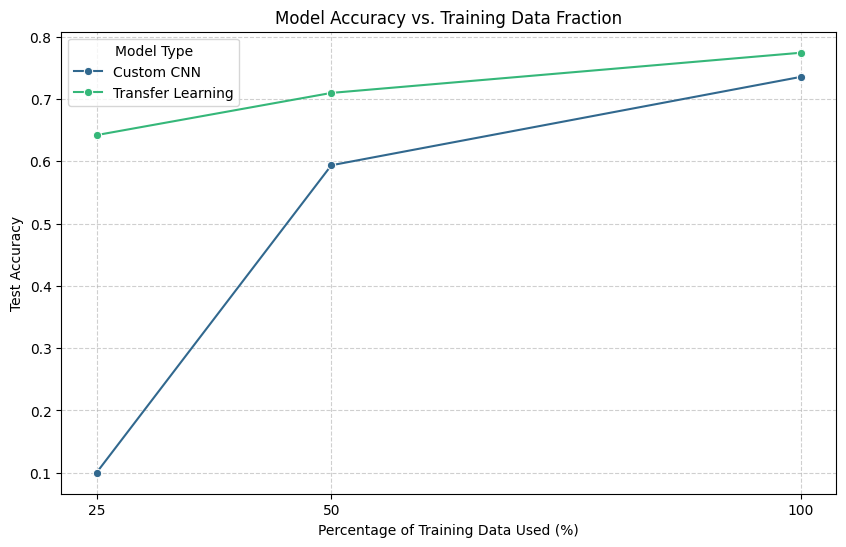

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Convert results to a pandas DataFrame for easier plotting
data = []
for frac, metrics in analysis_results.items():
    data.append({'Data Fraction': frac * 100, 'Model': 'Custom CNN', 'Accuracy': metrics['Custom']})
    data.append({'Data Fraction': frac * 100, 'Model': 'Transfer Learning', 'Accuracy': metrics['Transfer Learning']})

df_results = pd.DataFrame(data)

# Plotting the results
plt.figure(figsize=(10, 6))
sns.lineplot(x='Data Fraction', y='Accuracy', hue='Model', data=df_results, marker='o', palette='viridis')
plt.title('Model Accuracy vs. Training Data Fraction')
plt.xlabel('Percentage of Training Data Used (%)')
plt.ylabel('Test Accuracy')
plt.xticks(df_results['Data Fraction'].unique())
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Model Type')
plt.show()